Running simulation for 5-armed bandit …
Running simulation for 10-armed bandit …
Running simulation for 20-armed bandit …


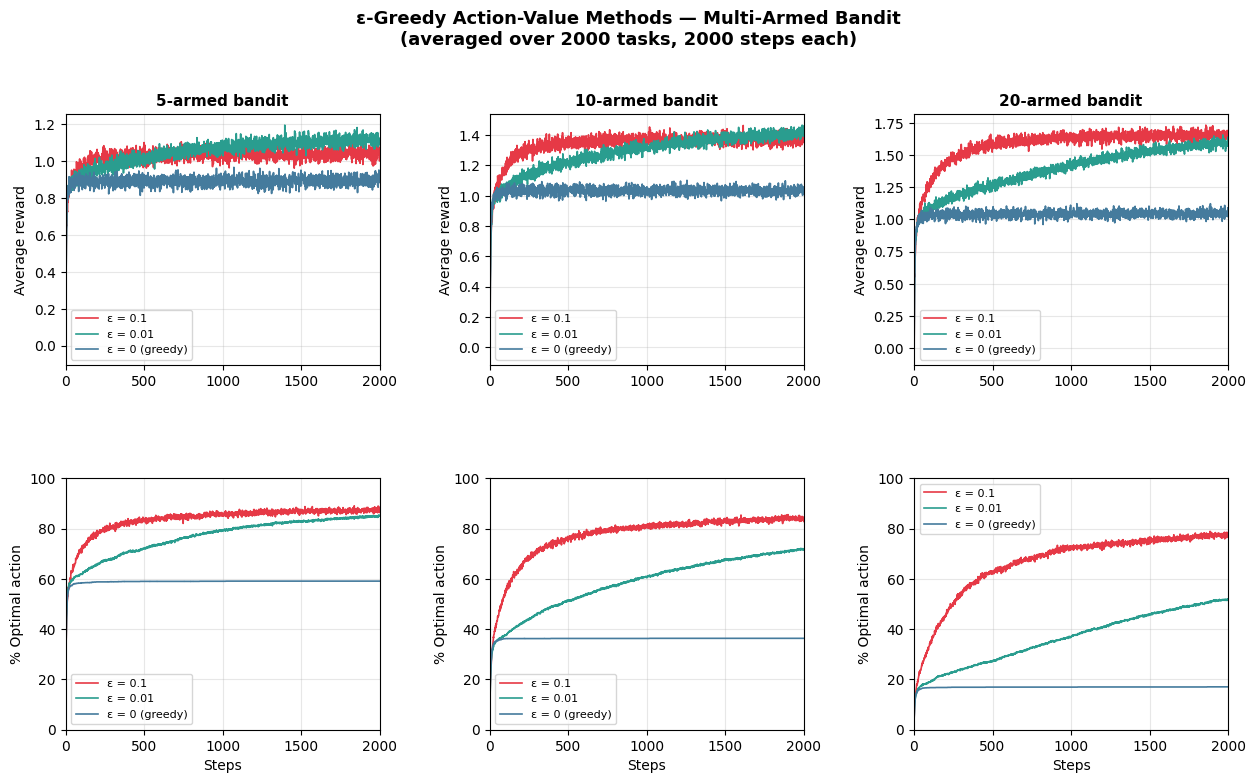

Saved bandit_results.png


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

"""A custom NArmedBandit class generates:
•   A vector of true action values sampled from a normal distribution - q*(a) ~ N(0,1)
•   A reward function that adds Gaussian noise to the true action value. When arm a is pulled at time step t, the reward received is drawn from a normal distribution centred on – q*(a): Rt ~ N(q*(a), 1)
•   Identification of the optimal arm for evaluation purposes
•   The optimal arm a* is the arm with the highest true value: a* = argmax_a q*(a).
Except for the reward after each pull, neither q*(a) nor the identity of a* is known to the agent.
Each simulation task creates a new bandit instance, to make sure independent experimental trials occur."""

class NArmedBandit:
    def __init__(self, n_arms):
        self.n_arms = n_arms
        self.q_true = np.random.randn(n_arms)
        self.optimal_arm = np.argmax(self.q_true)

    def pull(self, arm):

        return self.q_true[arm] + np.random.randn()

class EpsilonGreedyAgent:

    def __init__(self, n_arms, epsilon):
        self.n_arms  = n_arms
        self.epsilon = epsilon
        # Estimated action values, initialised to 0
        self.Q = np.zeros(n_arms)
        # Count of how many times each arm has been pulled
        self.N = np.zeros(n_arms, dtype=int)

    def select_action(self):
        """ε-greedy action selection."""
        if np.random.rand() < self.epsilon:
            # Exploring random actions uniformly
            return np.random.randint(self.n_arms)
        else:
            # Exploiting break ties randomly among max arms
            max_q = np.max(self.Q)
            best_arms = np.where(self.Q == max_q)[0]
            return np.random.choice(best_arms)

    def update(self, arm, reward):
        self.N[arm] += 1
        # Step size alpha = 1/N(arm) is sample average
        self.Q[arm] += (reward - self.Q[arm]) / self.N[arm]


def run_simulation(n_arms, epsilons, n_tasks=2000, n_steps=2000):

    avg_rewards = np.zeros((len(epsilons), n_steps))
    pct_optimal = np.zeros((len(epsilons), n_steps))

    for task in range(n_tasks):
        # new bandit assigned for every task
        bandit = NArmedBandit(n_arms)

        for eps_idx, eps in enumerate(epsilons):
            agent = EpsilonGreedyAgent(n_arms, eps)

            for step in range(n_steps):
                arm    = agent.select_action()
                reward = bandit.pull(arm)
                agent.update(arm, reward)

                avg_rewards[eps_idx, step] += reward
                if arm == bandit.optimal_arm:
                    pct_optimal[eps_idx, step] += 1

    # Average over tasks
    avg_rewards /= n_tasks
    pct_optimal  = pct_optimal / n_tasks * 100
    return avg_rewards, pct_optimal


COLORS = ['#e63946', '#2a9d8f', '#457b9d']
LABELS = {0.1: 'ε = 0.1', 0.01: 'ε = 0.01', 0.0: 'ε = 0 (greedy)'}

def plot_results(avg_rewards, pct_optimal, epsilons, n_arms, ax1, ax2):
    steps = np.arange(1, avg_rewards.shape[1] + 1)
    for i, eps in enumerate(epsilons):
        ax1.plot(steps, avg_rewards[i], color=COLORS[i],
                 label=LABELS[eps], linewidth=1.2)
        ax2.plot(steps, pct_optimal[i], color=COLORS[i],
                 label=LABELS[eps], linewidth=1.2)

    ax1.set_ylabel('Average reward', fontsize=10)
    ax1.set_title(f'{n_arms}-armed bandit', fontsize=11, fontweight='bold')
    ax1.legend(fontsize=8)
    ax1.set_xlim(0, avg_rewards.shape[1])
    ax1.grid(alpha=0.3)

    ax2.set_ylabel('% Optimal action', fontsize=10)
    ax2.set_xlabel('Steps', fontsize=10)
    ax2.legend(fontsize=8)
    ax2.set_xlim(0, avg_rewards.shape[1])
    ax2.set_ylim(0, 100)
    ax2.grid(alpha=0.3)


if __name__ == '__main__':
    np.random.seed(42)

    EPSILONS  = [0.1, 0.01, 0.0]
    ARM_SIZES = [5, 10, 20]
    N_TASKS   = 2000
    N_STEPS   = 2000

    fig, axes = plt.subplots(
        nrows=2, ncols=3,
        figsize=(15, 8),
        gridspec_kw={'hspace': 0.45, 'wspace': 0.35}
    )

    fig.suptitle(
        'ε-Greedy Action-Value Methods — Multi-Armed Bandit\n'
        f'(averaged over {N_TASKS} tasks, {N_STEPS} steps each)',
        fontsize=13, fontweight='bold', y=1.01
    )

    for col, n_arms in enumerate(ARM_SIZES):
        print(f'Running simulation for {n_arms}-armed bandit …')
        avg_rewards, pct_optimal = run_simulation(
            n_arms, EPSILONS, n_tasks=N_TASKS, n_steps=N_STEPS
        )
        plot_results(
            avg_rewards, pct_optimal, EPSILONS, n_arms,
            ax1=axes[0, col],
            ax2=axes[1, col]
        )

    plt.savefig('bandit_results.png', dpi=150,
                bbox_inches='tight', facecolor='white')
    plt.show('bandit_results')
    print('Saved bandit_results.png')
    plt.close()